# Bone Age Prediction from Hand X-rays with Deep Learning

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/vahid-karami/bone-age-prediction/blob/main/bone_age_prediction.ipynb)

**Author:** Vahid Karami

Skeletal **bone age** is read from a left-hand X-ray and compared with the child's real age to diagnose growth and endocrine disorders.
Manual reading (Greulich-Pyle atlas) is slow and varies between radiologists.

This notebook trains a CNN that predicts bone age **in months** from a hand radiograph plus the patient's sex, on the public
[RSNA Pediatric Bone Age](https://www.kaggle.com/datasets/kmader/rsna-bone-age) dataset.

**Pipeline**
1. Setup
2. Data
3. Preprocessing: aspect-preserving resize, padding, CLAHE
4. Stratified train / validation / test split
5. `tf.data` input pipeline
6. Model: Xception (ImageNet) + sex branch
7. Two-phase training: frozen backbone, then fine-tuning
8. Evaluation on a held-out test set: MAE with 95% CI, subgroup analysis, Bland-Altman
9. Explainability with Grad-CAM

> Run on Colab with a GPU: *Runtime > Change runtime type > T4 GPU*.

## 1. Setup

In [1]:
import json
import os
import random
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.model_selection import train_test_split
from tensorflow import keras
from tensorflow.keras import layers

print("TensorFlow", tf.__version__, "| GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow 2.21.0 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
SEED = 42
IMG_SIZE = 320            # images are letterboxed to IMG_SIZE x IMG_SIZE
BATCH_SIZE = 32
WARMUP_EPOCHS = 5         # phase 1: train only the new head (backbone frozen)
FINETUNE_EPOCHS = 40      # phase 2: fine-tune the whole network (early stopping usually ends it sooner)
BACKBONE_WEIGHTS = "imagenet"

WORK_DIR = Path("work")         # preprocessed images and model checkpoints (not committed)
RESULTS_DIR = Path("results")   # figures and metrics (committed to GitHub)
WORK_DIR.mkdir(exist_ok=True)
RESULTS_DIR.mkdir(exist_ok=True)

keras.utils.set_random_seed(SEED)   # seeds Python, NumPy and TensorFlow

if tf.config.list_physical_devices("GPU"):
    keras.mixed_precision.set_global_policy("mixed_float16")   # ~2x faster on T4

## 2. Data

**RSNA Pediatric Bone Age Challenge (2017):** 12,611 left-hand radiographs of children aged 0-19,
each labelled by radiologists with bone age in months, plus the patient's sex.
There is one image per patient, so a random image split is also a **patient-level split** (no leakage between sets).

The dataset is public and is downloaded with `kagglehub`; no API key is needed.

In [3]:
import kagglehub

DATA_DIR = Path(kagglehub.dataset_download("kmader/rsna-bone-age"))
labels_csv = next(DATA_DIR.rglob("boneage-training-dataset.csv"))
img_dir = next(p for p in DATA_DIR.rglob("boneage-training-dataset") if p.is_dir() and any(p.glob("*.png")))
print(labels_csv, img_dir, sep="\n")

100%|██████████| 9.29G/9.29G [01:59<00:00, 83.6MB/s]

Extracting files...


/root/.cache/kagglehub/datasets/kmader/rsna-bone-age/versions/2/boneage-training-dataset.csv
/root/.cache/kagglehub/datasets/kmader/rsna-bone-age/versions/2/boneage-training-dataset/boneage-training-dataset


In [4]:
df = pd.read_csv(labels_csv)
df["male"] = df["male"].astype(int)
df["path_raw"] = df["id"].apply(lambda i: str(img_dir / f"{i}.png"))
print(df.shape)
df.head()

(12611, 4)


,id,boneage,male,path_raw
0,1377,180,0,/root/.cache/kagglehub/datasets/kmader/rsna-bo...
1,1378,12,0,/root/.cache/kagglehub/datasets/kmader/rsna-bo...
2,1379,94,0,/root/.cache/kagglehub/datasets/kmader/rsna-bo...
3,1380,120,1,/root/.cache/kagglehub/datasets/kmader/rsna-bo...
4,1381,82,0,/root/.cache/kagglehub/datasets/kmader/rsna-bo...


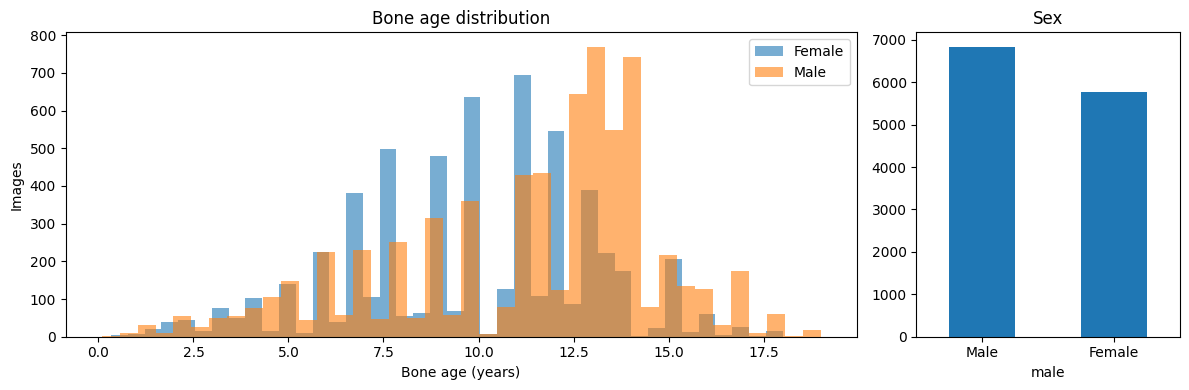

count    12611.0
mean       127.3
std         41.2
min          1.0
25%         96.0
50%        132.0
75%        156.0
max        228.0
Name: boneage, dtype: float64


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={"width_ratios": [3, 1]})
for male, name in [(0, "Female"), (1, "Male")]:
    axes[0].hist(df.loc[df.male == male, "boneage"] / 12, bins=40, alpha=0.6, label=name)
axes[0].set(xlabel="Bone age (years)", ylabel="Images", title="Bone age distribution")
axes[0].legend()
df["male"].map({0: "Female", 1: "Male"}).value_counts().plot.bar(ax=axes[1], rot=0, title="Sex")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "data_distribution.png", dpi=120)
plt.show()
print(df["boneage"].describe().round(1))

## 3. Preprocessing

The raw radiographs vary in size (often around 1500 x 2000 px), aspect ratio and exposure. Each image is:
1. resized so its longest side is `IMG_SIZE`, **keeping the aspect ratio** (no stretching of the hand),
2. zero-padded to a square,
3. enhanced with **CLAHE** (contrast-limited adaptive histogram equalization), which makes the growth plates clearer.

The processed copies go to a separate folder, so the original images are never modified. This runs once (about 5 minutes).

In [6]:
PROC_DIR = WORK_DIR / f"images_{IMG_SIZE}"
PROC_DIR.mkdir(parents=True, exist_ok=True)


def preprocess_image(src, dst, size=IMG_SIZE):
    img = cv2.imread(src, cv2.IMREAD_GRAYSCALE)
    h, w = img.shape
    scale = size / max(h, w)
    img = cv2.resize(img, (max(1, round(w * scale)), max(1, round(h * scale))), interpolation=cv2.INTER_AREA)
    canvas = np.zeros((size, size), np.uint8)
    y0, x0 = (size - img.shape[0]) // 2, (size - img.shape[1]) // 2
    canvas[y0:y0 + img.shape[0], x0:x0 + img.shape[1]] = img
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    cv2.imwrite(dst, clahe.apply(canvas))


df["path"] = df["id"].apply(lambda i: str(PROC_DIR / f"{i}.png"))
todo = [(s, d) for s, d in zip(df["path_raw"], df["path"]) if not os.path.exists(d)]
with ThreadPoolExecutor(max_workers=8) as pool:
    list(pool.map(lambda args: preprocess_image(*args), todo))
print(f"Preprocessed {len(todo)} images -> {PROC_DIR}")

Preprocessed 12611 images -> work/images_320


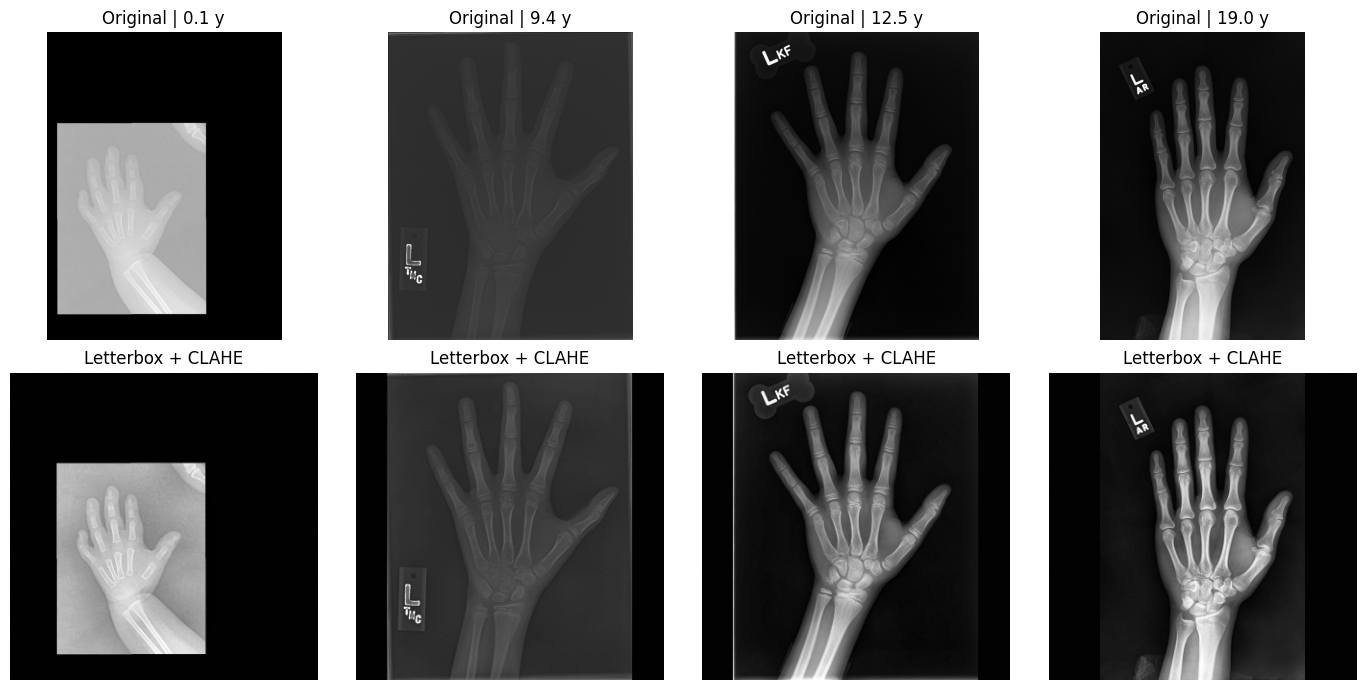

In [7]:
samples = df.sort_values("boneage").iloc[np.linspace(0, len(df) - 1, 4).astype(int)]
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for j, (_, r) in enumerate(samples.iterrows()):
    axes[0, j].imshow(cv2.imread(r.path_raw, cv2.IMREAD_GRAYSCALE), cmap="gray")
    axes[0, j].set_title(f"Original | {r.boneage / 12:.1f} y")
    axes[1, j].imshow(cv2.imread(r.path, cv2.IMREAD_GRAYSCALE), cmap="gray")
    axes[1, j].set_title("Letterbox + CLAHE")
for ax in axes.flat:
    ax.axis("off")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "preprocessing.png", dpi=100)
plt.show()

## 4. Train / validation / test split

70 / 15 / 15, **stratified by sex and bone-age decile** so all three sets have the same age and sex mix.
The test set is used **only once**, for the final evaluation.

In [8]:
strata = df["male"].astype(str) + "_" + pd.qcut(df["boneage"], 10, labels=False, duplicates="drop").astype(str)
train_df, temp_df = train_test_split(df, test_size=0.30, stratify=strata, random_state=SEED)
val_df, test_df = train_test_split(temp_df, test_size=0.50, stratify=strata.loc[temp_df.index], random_state=SEED)

splits = {"train": train_df, "val": val_df, "test": test_df}
for name, d in splits.items():
    print(f"{name:5s} {len(d):5d} images | mean bone age {d.boneage.mean() / 12:5.2f} y | male {d.male.mean():.0%}")
pd.concat([d[["id"]].assign(split=name) for name, d in splits.items()]).to_csv(RESULTS_DIR / "split.csv", index=False)

train  8827 images | mean bone age 10.61 y | male 54%
val    1892 images | mean bone age 10.62 y | male 54%
test   1892 images | mean bone age 10.61 y | male 54%


## 5. Input pipeline

Decoded images are cached in RAM as `uint8` (about 1.3 GB), so the PNGs are read only once.
Data augmentation is part of the model (next section), so it runs on the GPU and only during training.

In [9]:
AUTOTUNE = tf.data.AUTOTUNE


def decode(path):
    img = tf.io.decode_png(tf.io.read_file(path), channels=1)
    return tf.ensure_shape(img, (IMG_SIZE, IMG_SIZE, 1))


def to_inputs(img, male, age):
    image = tf.image.grayscale_to_rgb(tf.cast(img, tf.float32))   # ImageNet backbones expect 3 channels
    return {"image": image, "male": tf.expand_dims(male, -1)}, age


def make_dataset(d, training):
    ds = tf.data.Dataset.from_tensor_slices(
        (d["path"].values, d["male"].values.astype("float32"), d["boneage"].values.astype("float32")))
    ds = ds.map(lambda p, m, y: (decode(p), m, y), num_parallel_calls=AUTOTUNE).cache()
    if training:
        ds = ds.shuffle(2048, seed=SEED, reshuffle_each_iteration=True)
    return ds.map(to_inputs, num_parallel_calls=AUTOTUNE).batch(BATCH_SIZE).prefetch(AUTOTUNE)


train_ds = make_dataset(train_df, training=True)
val_ds = make_dataset(val_df, training=False)
test_ds = make_dataset(test_df, training=False)    # not shuffled: prediction order == test_df order

## 6. Model

- **Backbone:** Xception pretrained on ImageNet. The backbone always runs in inference mode, so its BatchNorm statistics stay frozen during fine-tuning.
- **Sex branch:** skeletal maturation differs between boys and girls, so sex is passed to the network as a second input.
- **Output:** the last layer predicts a z-score and rescales it to **months** (`mean + std * z`). Loss and metrics are therefore in months, and the saved model needs no custom objects.
- **Augmentation** (training only): small rotation, shift and zoom, contrast jitter, horizontal flip.

In [10]:
y_mean, y_std = float(train_df["boneage"].mean()), float(train_df["boneage"].std())

augment = keras.Sequential([
    layers.RandomRotation(0.05, fill_mode="constant"),          # +/- 18 degrees
    layers.RandomTranslation(0.08, 0.08, fill_mode="constant"),
    layers.RandomZoom(0.1, fill_mode="constant"),
    layers.RandomContrast(0.2),
    layers.RandomFlip("horizontal"),
], name="augment")
preprocess = layers.Rescaling(1 / 127.5, offset=-1, name="xception_preprocess")   # [0, 255] -> [-1, 1]
backbone = keras.applications.Xception(include_top=False, weights=BACKBONE_WEIGHTS, input_shape=(IMG_SIZE, IMG_SIZE, 3))


def build_head(feature_shape):
    features = keras.Input(feature_shape, name="features")
    male = keras.Input((1,), name="male")
    x = layers.GlobalAveragePooling2D()(features)
    s = layers.Dense(32, activation="relu", name="sex_embedding")(male)
    x = layers.Concatenate()([x, s])
    x = layers.Dropout(0.3)(x)
    x = layers.Dense(256, activation="relu")(x)
    x = layers.Dropout(0.3)(x)
    z = layers.Dense(1, dtype="float32", name="z_score")(x)
    months = layers.Rescaling(y_std, offset=y_mean, dtype="float32", name="bone_age_months")(z)
    return keras.Model([features, male], months, name="head")


head = build_head(backbone.output.shape[1:])

image_in = keras.Input((IMG_SIZE, IMG_SIZE, 3), name="image")
male_in = keras.Input((1,), name="male")
features = backbone(preprocess(augment(image_in)), training=False)
model = keras.Model([image_in, male_in], head([features, male_in]), name="bone_age_xception")
model.summary()

83683744/83683744 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "bone_age_xception"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ image (InputLayer)  │ (None, 320, 320,  │          0 │ -                 │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ augment             │ (None, 320, 320,  │          0 │ image[0][0]       │
│ (Sequential)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ xception_preprocess │ (None, 320, 320,  │          0 │ augment[0][0]     │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ xception            │ (None, 10, 10,    │ 20,861,480 │ xception_preproc… │
│ (Functional)        │ 2048)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ male (InputLayer)   │ (None, 1)         │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ head (Functional)   │ (None, 1)         │    533,057 │ xception[0][0],   │
│                     │                   │            │ male[0][0]        │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 21,394,537 (81.61 MB)

 Trainable params: 21,340,009 (81.41 MB)

 Non-trainable params: 54,528 (213.00 KB)

## 7. Training

**Phase 1:** freeze the backbone and train only the new head (lr = 1e-3), so the random head doesn't damage the pretrained features.

**Phase 2:** unfreeze everything and fine-tune with a lower learning rate (1e-4). This phase uses:
- `ReduceLROnPlateau`: halve the learning rate when validation MAE stops improving,
- `EarlyStopping`: stop after 8 epochs without improvement and restore the best weights,
- `ModelCheckpoint`: keep the best model on disk.

The model is validated on the **full** validation set every epoch.

In [11]:
def compile_model(lr):
    model.compile(
        optimizer=keras.optimizers.Adam(lr),
        loss="mean_absolute_error",
        metrics=[keras.metrics.MeanAbsoluteError(name="mae_months"),
                 keras.metrics.RootMeanSquaredError(name="rmse_months")],
    )


# Phase 1: head only
backbone.trainable = False
compile_model(1e-3)
hist1 = model.fit(train_ds, validation_data=val_ds, epochs=WARMUP_EPOCHS)

Epoch 1/5
276/276 ━━━━━━━━━━━━━━━━━━━━ 76s 218ms/step - loss: 22.7554 - mae_months: 22.7554 - rmse_months: 29.1970 - val_loss: 17.8386 - val_mae_months: 17.8386 - val_rmse_months: 23.1435
Epoch 2/5
276/276 ━━━━━━━━━━━━━━━━━━━━ 59s 214ms/step - loss: 19.2937 - mae_months: 19.2937 - rmse_months: 24.8339 - val_loss: 18.9135 - val_mae_months: 18.9135 - val_rmse_months: 23.3820
Epoch 3/5
276/276 ━━━━━━━━━━━━━━━━━━━━ 60s 218ms/step - loss: 18.2705 - mae_months: 18.2705 - rmse_months: 23.5932 - val_loss: 18.8586 - val_mae_months: 18.8586 - val_rmse_months: 23.4415
Epoch 4/5
276/276 ━━━━━━━━━━━━━━━━━━━━ 60s 219ms/step - loss: 18.2859 - mae_months: 18.2859 - rmse_months: 23.5123 - val_loss: 19.2972 - val_mae_months: 19.2972 - val_rmse_months: 23.9983
Epoch 5/5
276/276 ━━━━━━━━━━━━━━━━━━━━ 60s 217ms/step - loss: 18.0130 - mae_months: 18.0130 - rmse_months: 23.0185 - val_loss: 18.3130 - val_mae_months: 18.3130 - val_rmse_months: 22.9700


In [12]:
# Phase 2: fine-tune the whole network
backbone.trainable = True
compile_model(1e-4)
callbacks = [
    keras.callbacks.ModelCheckpoint(str(WORK_DIR / "best_model.keras"), monitor="val_mae_months", mode="min", save_best_only=True),
    keras.callbacks.ReduceLROnPlateau(monitor="val_mae_months", mode="min", factor=0.5, patience=3, min_lr=1e-6, verbose=1),
    keras.callbacks.EarlyStopping(monitor="val_mae_months", mode="min", patience=8, restore_best_weights=True, verbose=1),
    keras.callbacks.CSVLogger(str(RESULTS_DIR / "training_log.csv")),
]
hist2 = model.fit(train_ds, validation_data=val_ds, initial_epoch=WARMUP_EPOCHS,
                  epochs=WARMUP_EPOCHS + FINETUNE_EPOCHS, callbacks=callbacks)

Epoch 6/45
276/276 ━━━━━━━━━━━━━━━━━━━━ 293s 887ms/step - loss: 14.8199 - mae_months: 14.8199 - rmse_months: 20.0193 - val_loss: 11.5716 - val_mae_months: 11.5716 - val_rmse_months: 14.6861 - learning_rate: 1.0000e-04
Epoch 7/45
276/276 ━━━━━━━━━━━━━━━━━━━━ 224s 811ms/step - loss: 11.1196 - mae_months: 11.1196 - rmse_months: 14.5175 - val_loss: 10.7041 - val_mae_months: 10.7041 - val_rmse_months: 13.8028 - learning_rate: 1.0000e-04
Epoch 8/45
276/276 ━━━━━━━━━━━━━━━━━━━━ 229s 830ms/step - loss: 10.1220 - mae_months: 10.1220 - rmse_months: 13.1908 - val_loss: 9.5152 - val_mae_months: 9.5152 - val_rmse_months: 12.4956 - learning_rate: 1.0000e-04
Epoch 9/45
276/276 ━━━━━━━━━━━━━━━━━━━━ 230s 832ms/step - loss: 9.4620 - mae_months: 9.4620 - rmse_months: 12.2425 - val_loss: 8.6266 - val_mae_months: 8.6266 - val_rmse_months: 11.2885 - learning_rate: 1.0000e-04
Epoch 10/45
276/276 ━━━━━━━━━━━━━━━━━━━━ 218s 789ms/step - loss: 9.2208 - mae_months: 9.2208 - rmse_months: 11.9924 - val_loss: 8.7159

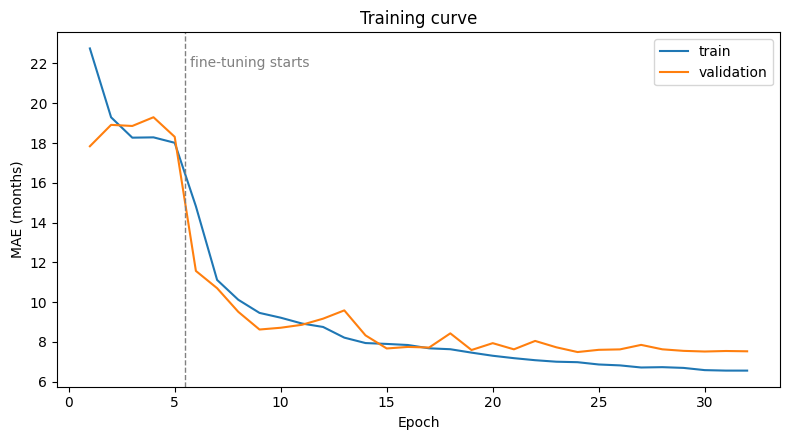

Best validation MAE: 7.49 months


In [13]:
history = {k: hist1.history[k] + hist2.history[k] for k in ["mae_months", "val_mae_months", "loss", "val_loss"]}
epochs = np.arange(1, len(history["mae_months"]) + 1)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(epochs, history["mae_months"], label="train")
ax.plot(epochs, history["val_mae_months"], label="validation")
ax.axvline(WARMUP_EPOCHS + 0.5, color="gray", ls="--", lw=1)
ax.text(WARMUP_EPOCHS + 0.7, ax.get_ylim()[1] * 0.95, "fine-tuning starts", color="gray", va="top")
ax.set(xlabel="Epoch", ylabel="MAE (months)", title="Training curve")
ax.legend()
plt.tight_layout()
plt.savefig(RESULTS_DIR / "training_curve.png", dpi=120)
plt.show()
print(f"Best validation MAE: {min(history['val_mae_months']):.2f} months")

## 8. Evaluation on the held-out test set

The test set has not been seen during training or model selection. Reported:
- **MAE** (months) with a **95% bootstrap confidence interval** (2,000 resamples),
- RMSE, median absolute error, R², and the share of predictions within ±12 months,
- a **baseline** that always predicts the training-set mean, to show how much the model learned,
- **subgroup MAE** by sex and age group, to check the model works equally well for everyone.

In [14]:
y_true = test_df["boneage"].to_numpy(float)
y_pred = model.predict(test_ds, verbose=0).ravel().astype(float)
err = y_pred - y_true
abs_err = np.abs(err)

rng = np.random.default_rng(SEED)
boot = [abs_err[rng.integers(0, len(abs_err), len(abs_err))].mean() for _ in range(2000)]
ci_low, ci_high = np.percentile(boot, [2.5, 97.5])

res = test_df[["id", "male", "boneage"]].assign(predicted=y_pred.round(1), abs_error=abs_err.round(1))
res["sex"] = res["male"].map({0: "Female", 1: "Male"})
res["age_group"] = pd.cut(res["boneage"] / 12, [0, 5, 10, 15, 20], right=False,
                          labels=["0-5 y", "5-10 y", "10-15 y", "15-19 y"])

metrics = {
    "test_images": int(len(y_true)),
    "mae_months": round(float(abs_err.mean()), 2),
    "mae_95ci_months": [round(float(ci_low), 2), round(float(ci_high), 2)],
    "rmse_months": round(float(np.sqrt(np.mean(err ** 2))), 2),
    "median_abs_error_months": round(float(np.median(abs_err)), 2),
    "r2": round(float(1 - np.sum(err ** 2) / np.sum((y_true - y_true.mean()) ** 2)), 3),
    "within_12_months": round(float(np.mean(abs_err <= 12)), 3),
    "baseline_mae_months": round(float(np.abs(y_true - y_mean).mean()), 2),
    "mae_by_sex": res.groupby("sex")["abs_error"].mean().round(2).to_dict(),
    "mae_by_age_group": res.groupby("age_group", observed=True)["abs_error"].mean().round(2).to_dict(),
}
res.to_csv(RESULTS_DIR / "test_predictions.csv", index=False)
(RESULTS_DIR / "metrics.json").write_text(json.dumps(metrics, indent=2))

print(f"Test MAE: {metrics['mae_months']} months (95% CI {ci_low:.2f}-{ci_high:.2f})")
print(f"Baseline (predict mean): {metrics['baseline_mae_months']} months")
pd.concat([
    res.groupby("sex")["abs_error"].agg(["count", "mean"]),
    res.groupby("age_group", observed=True)["abs_error"].agg(["count", "mean"]),
]).rename(columns={"count": "images", "mean": "MAE (months)"}).round(2)

Test MAE: 7.35 months (95% CI 7.07-7.63)
Baseline (predict mean): 33.43 months


,images,MAE (months)
Female,867,7.79
Male,1025,6.97
0-5 y,126,8.84
5-10 y,514,8.08
10-15 y,1091,6.79
15-19 y,161,7.58


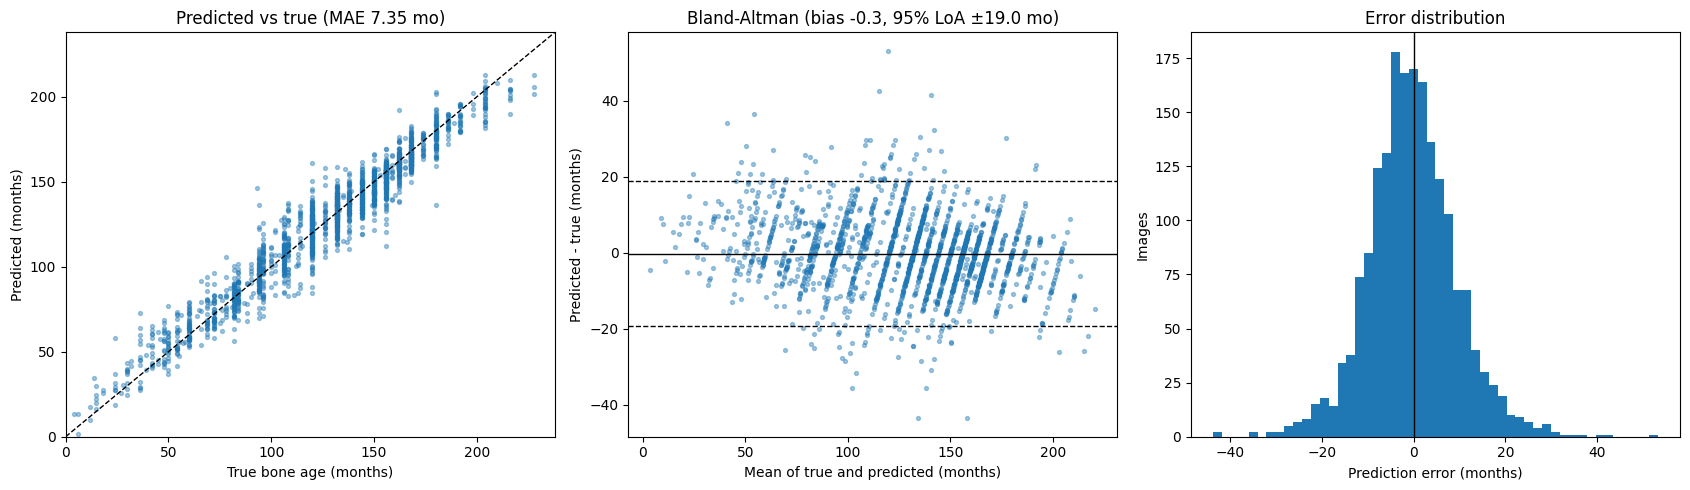

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

lim = [0, max(y_true.max(), y_pred.max()) + 10]
axes[0].scatter(y_true, y_pred, s=8, alpha=0.4)
axes[0].plot(lim, lim, "k--", lw=1)
axes[0].set(xlim=lim, ylim=lim, xlabel="True bone age (months)", ylabel="Predicted (months)",
            title=f"Predicted vs true (MAE {metrics['mae_months']} mo)")

mean_pair = (y_true + y_pred) / 2
bias, loa = err.mean(), 1.96 * err.std()
axes[1].scatter(mean_pair, err, s=8, alpha=0.4)
for v, ls in [(bias, "-"), (bias + loa, "--"), (bias - loa, "--")]:
    axes[1].axhline(v, color="k", ls=ls, lw=1)
axes[1].set(xlabel="Mean of true and predicted (months)", ylabel="Predicted - true (months)",
            title=f"Bland-Altman (bias {bias:.1f}, 95% LoA ±{loa:.1f} mo)")

axes[2].hist(err, bins=50)
axes[2].axvline(0, color="k", lw=1)
axes[2].set(xlabel="Prediction error (months)", ylabel="Images", title="Error distribution")

plt.tight_layout()
plt.savefig(RESULTS_DIR / "evaluation.png", dpi=120)
plt.show()

## 9. Explainability: Grad-CAM

Grad-CAM highlights the image regions that most increase the predicted age.
A trustworthy model should focus on the **growth plates (epiphyses) of the phalanges, metacarpals and the carpal bones**,
the same regions radiologists use, rather than on labels, borders or background.

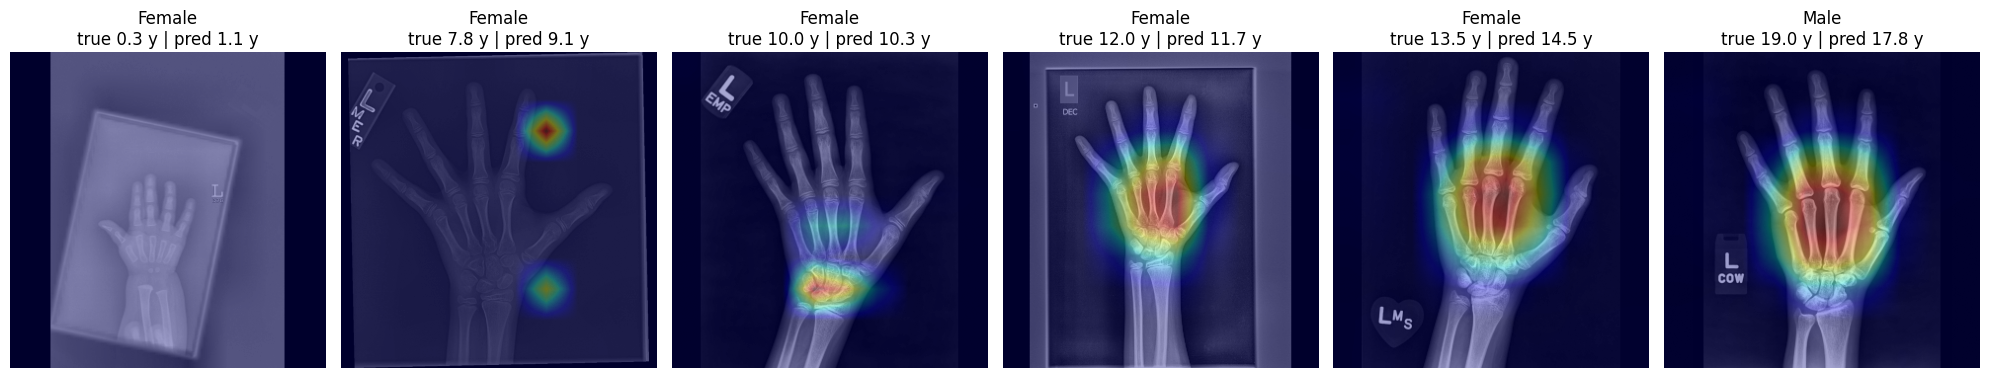

In [16]:
def grad_cam(image_u8, male):
    img = tf.image.grayscale_to_rgb(tf.cast(image_u8[None], tf.float32))
    with tf.GradientTape() as tape:
        feats = backbone(preprocess(img), training=False)
        tape.watch(feats)
        pred = head([feats, tf.constant([[male]], tf.float32)], training=False)
    grads = tf.cast(tape.gradient(pred, feats), tf.float32)
    feats = tf.cast(feats, tf.float32)
    weights = tf.reduce_mean(grads, axis=(1, 2))                       # one weight per channel
    cam = tf.nn.relu(tf.reduce_sum(feats * weights[:, None, None, :], axis=-1))[0]
    cam = cam / (tf.reduce_max(cam) + 1e-8)
    cam = tf.image.resize(cam[..., None], (IMG_SIZE, IMG_SIZE))[..., 0].numpy()
    return cam, float(pred[0, 0])


examples = res.sort_values("boneage").iloc[np.linspace(0, len(res) - 1, 6).astype(int)]
fig, axes = plt.subplots(1, 6, figsize=(20, 4.5))
for ax, (_, r) in zip(axes, examples.iterrows()):
    img = cv2.imread(str(PROC_DIR / f"{r.id}.png"), cv2.IMREAD_GRAYSCALE)
    cam, pred = grad_cam(img[..., None], r.male)
    ax.imshow(img, cmap="gray")
    ax.imshow(cam, cmap="jet", alpha=0.35)
    ax.set_title(f"{r.sex}\ntrue {r.boneage / 12:.1f} y | pred {pred / 12:.1f} y")
    ax.axis("off")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "gradcam.png", dpi=110)
plt.show()

## 10. Save the model

The model is saved in the native Keras format. It's too large for the GitHub repository (about 80 MB),
so it's published separately as a GitHub Release asset.

In [17]:
model.save(WORK_DIR / "bone_age_xception.keras")

# Optional: keep a copy on Google Drive
# from google.colab import drive
# drive.mount("/content/drive")
# !cp work/bone_age_xception.keras /content/drive/MyDrive/

print(json.dumps(metrics, indent=2))

{
  "test_images": 1892,
  "mae_months": 7.35,
  "mae_95ci_months": [
    7.07,
    7.63
  ],
  "rmse_months": 9.71,
  "median_abs_error_months": 5.78,
  "r2": 0.944,
  "within_12_months": 0.822,
  "baseline_mae_months": 33.43,
  "mae_by_sex": {
    "Female": 7.79,
    "Male": 6.97
  },
  "mae_by_age_group": {
    "0-5 y": 8.84,
    "5-10 y": 8.08,
    "10-15 y": 6.79,
    "15-19 y": 7.58
  }
}


## Limitations

- Trained and tested on a **single dataset** (RSNA); there is no external validation on other hospitals or scanners.
- The labels are themselves radiologist readings with inter-observer variability, which puts a floor on achievable error.
- Images are downscaled to 320 px; challenge-winning solutions used higher resolution and model ensembles (MAE about 4.2 months).
- This is a research and portfolio project, **not a medical device**, and must not be used for clinical decisions.